In [17]:
import sys
import os
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

sys.path.append(os.path.join(os.getcwd(), '../'))
from utils import read_utils
from utils import plot_utils

In [18]:
import importlib
importlib.reload(read_utils)
importlib.reload(plot_utils)

<module 'utils.plot_utils' from '/home/julian-zim/Files/Cloud/OneDrive/OneFiles/Linux/ZimmerLab/MSc_Thesis/Workspace/hobe/organisms/mouse-2019-stringer/data_exploration/../utils/plot_utils.py'>

In [19]:
# read_ids = list(range(0, 8+1))
read_ids = [2, 3]
plot_id = 2

In [20]:
path = os.path.join(read_utils.get_data_path(), 'mouse-2019-stringer/6163622/sessions')

(file_ids, filenames,
 traces,
 continuous_behaviors,
 motion_pcs,
 motion_masks) = read_utils.get_data(path, read_ids, with_whisking=True)

In [21]:
# clear nan values
for i in range(len(file_ids)):
	# mask = motion_pcs[i][0].notna().all(axis=1)
	mask = continuous_behaviors[i].notna().all(axis=1)

	traces[i] = traces[i][mask]
	motion_pcs[i][0] = motion_pcs[i][0][mask]
	motion_pcs[i][1] = motion_pcs[i][1][mask]
	continuous_behaviors[i] = continuous_behaviors[i][mask]

# naive ID neurons
for i in range(len(file_ids)):
	traces[i].columns = pd.Index([
		f'{file_ids[i]:02d}_{n_id:03d}' for n_id in range(traces[i].shape[1])
	])

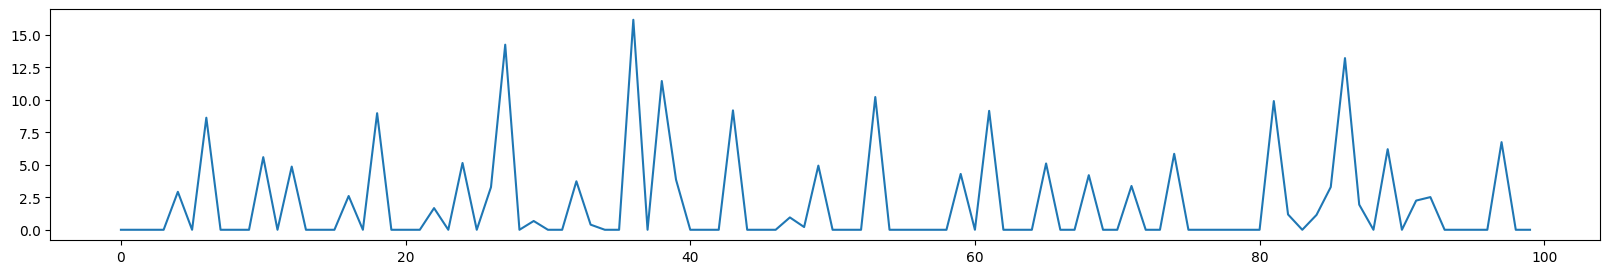

In [22]:
plt.figure(figsize=(20, 3))
plt.plot(traces[0].values[:100, 0])

Text(0.5, 1.0, 'Neuronal activity')

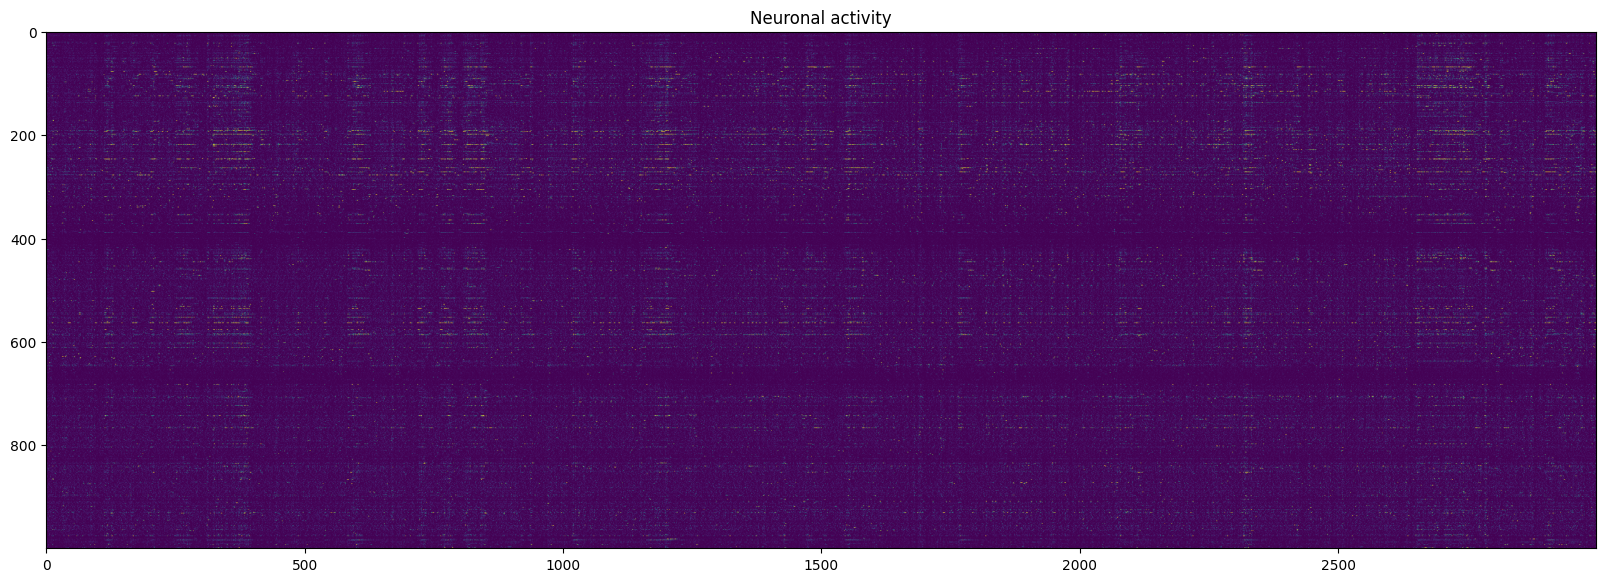

In [23]:
plt.figure(figsize=(20, 20))
plt.imshow(np.clip(traces[file_ids.index(plot_id)].values[:3000, :1000].T, 0, 500), cmap='viridis')
plt.title('Neuronal activity')

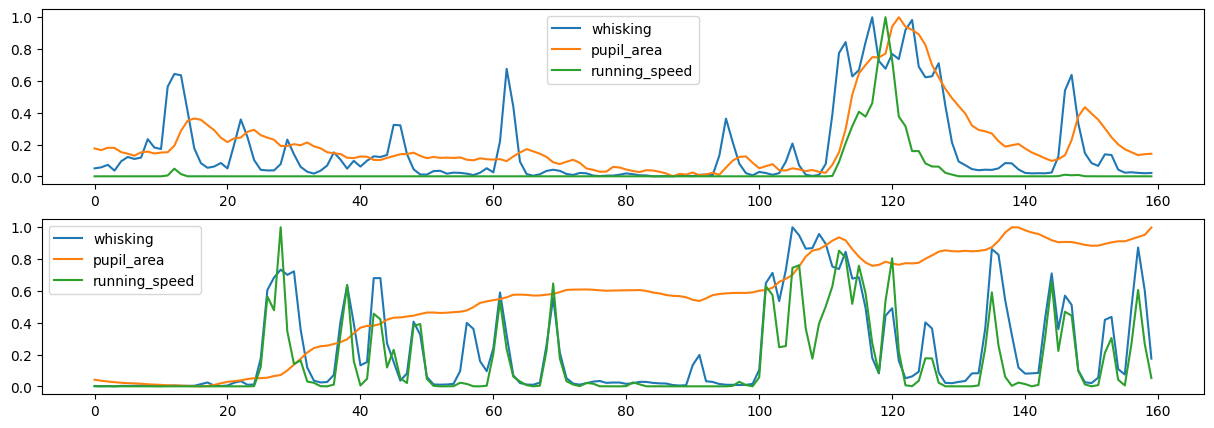

In [24]:
fig, ax = plt.subplots(len(file_ids), 1, squeeze=False, figsize=(15, 5))
for file_id in file_ids:
	whisking = continuous_behaviors[file_ids.index(file_id)][['whisking']].values[:160]
	running_speed = continuous_behaviors[file_ids.index(file_id)][['running_speed']].values[:160]
	pupil_area = continuous_behaviors[file_ids.index(file_id)][['pupil_area']].values[:160]

	whisking = (whisking - whisking.min()) / (whisking.max() - whisking.min())
	running_speed = (running_speed - running_speed.min()) / (running_speed.max() - running_speed.min())
	pupil_area = (pupil_area - pupil_area.min()) / (pupil_area.max() - pupil_area.min())

	ax[file_ids.index(file_id), 0].plot(whisking, label='whisking')
	ax[file_ids.index(file_id), 0].plot(pupil_area, label='pupil_area')
	ax[file_ids.index(file_id), 0].plot(running_speed, label='running_speed')
	ax[file_ids.index(file_id), 0].legend()

Text(0.5, 1.0, 'pupil com x (blue) and pupil com y (orange)')

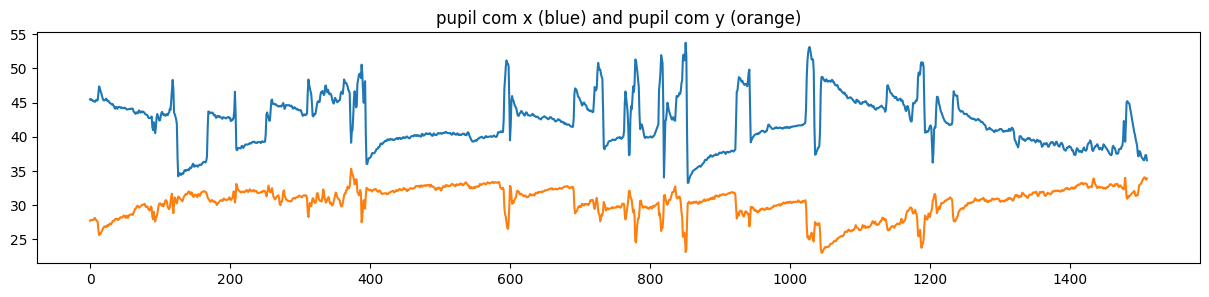

In [25]:
plt.figure(figsize=(15, 3))
plt.plot()
plt.plot(continuous_behaviors[file_ids.index(plot_id)]['pupil_com_x'].iloc[:1500])
plt.plot(continuous_behaviors[file_ids.index(plot_id)]['pupil_com_y'].iloc[:1500])
plt.title('pupil com x (blue) and pupil com y (orange)')

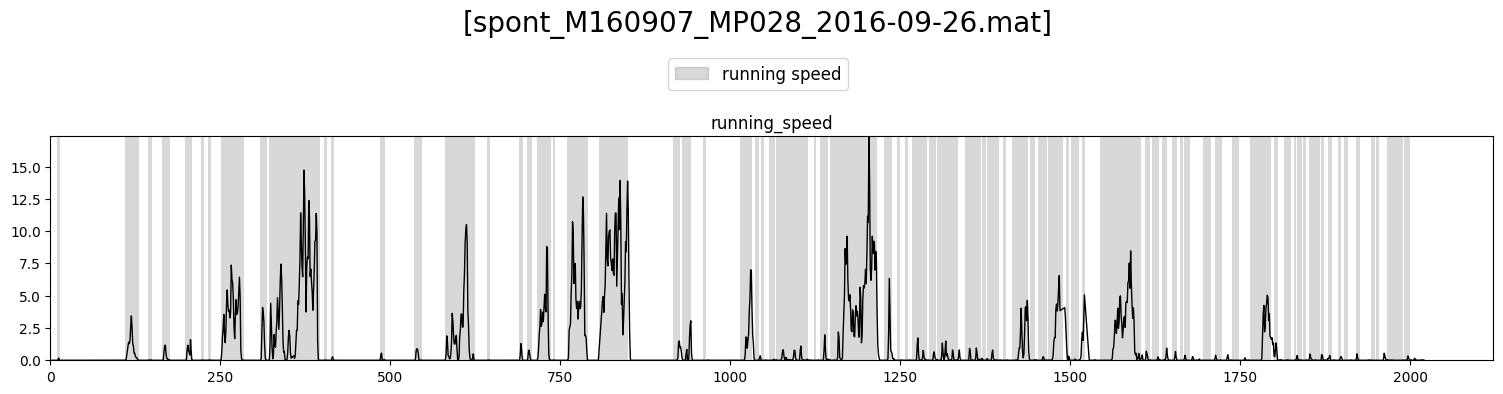

In [34]:
classes = continuous_behaviors[0][['running_speed']].values > np.quantile(continuous_behaviors[0][['running_speed']].values, 0.05)

plot_utils.plot_traces_states(f'[{filenames[file_ids.index(plot_id)]}]',
							  pd.DataFrame(data=classes[:2000] * 30, columns=continuous_behaviors[0][['running_speed']].columns),
							  [continuous_behaviors[0][['running_speed']].iloc[:2000]],
							  plots_per_row=1, ylimits=None)

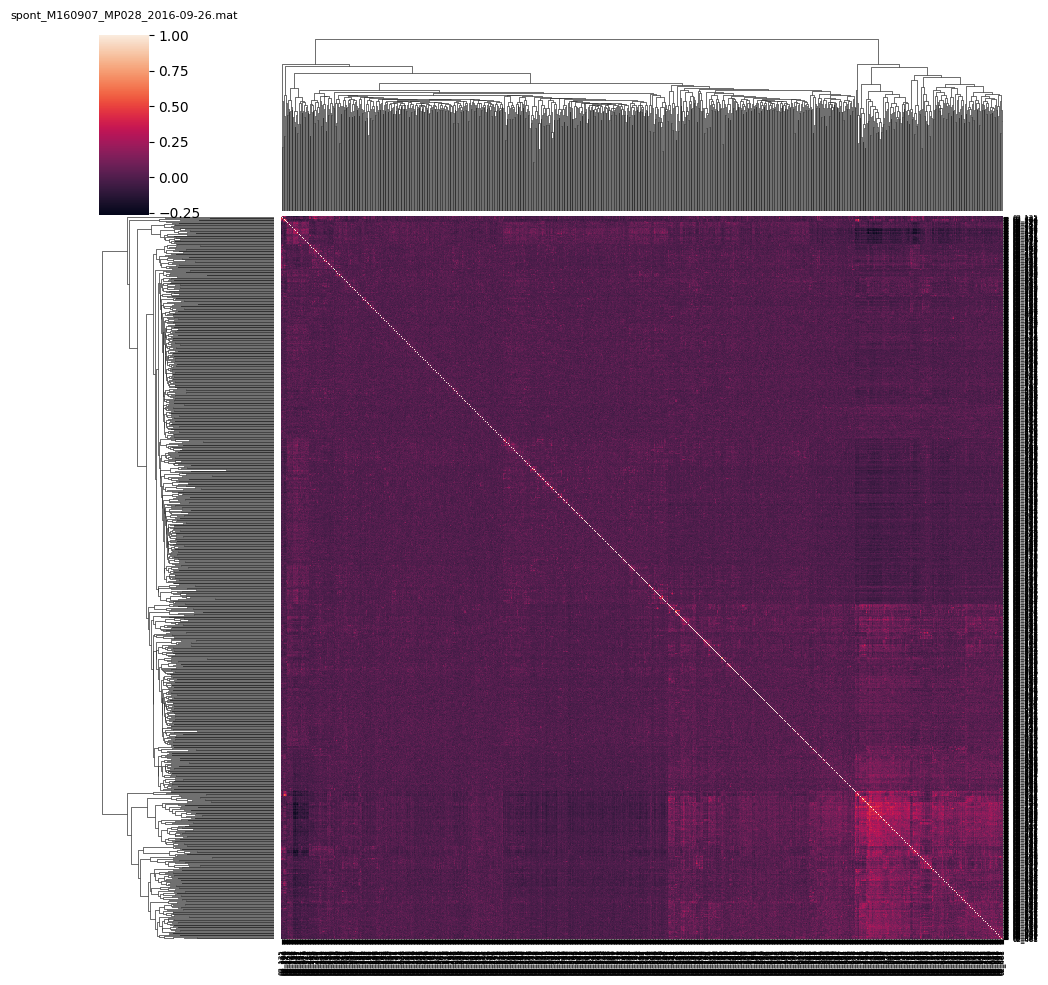

In [27]:
correlation = traces[file_ids.index(plot_id)].iloc[:1500, :1000].corr()
heatmap = sns.clustermap(correlation, yticklabels=True, xticklabels=True)
heatmap.ax_heatmap.set_yticklabels(heatmap.ax_heatmap.get_yticklabels(), fontsize=5)
heatmap.ax_heatmap.set_xticklabels(heatmap.ax_heatmap.get_xticklabels(), fontsize=5)
heatmap.ax_heatmap.tick_params(axis='x', bottom=True, top=False)

plt.title(f'{filenames[file_ids.index(plot_id)]}', y=1.05, fontsize=8)
plt.show()

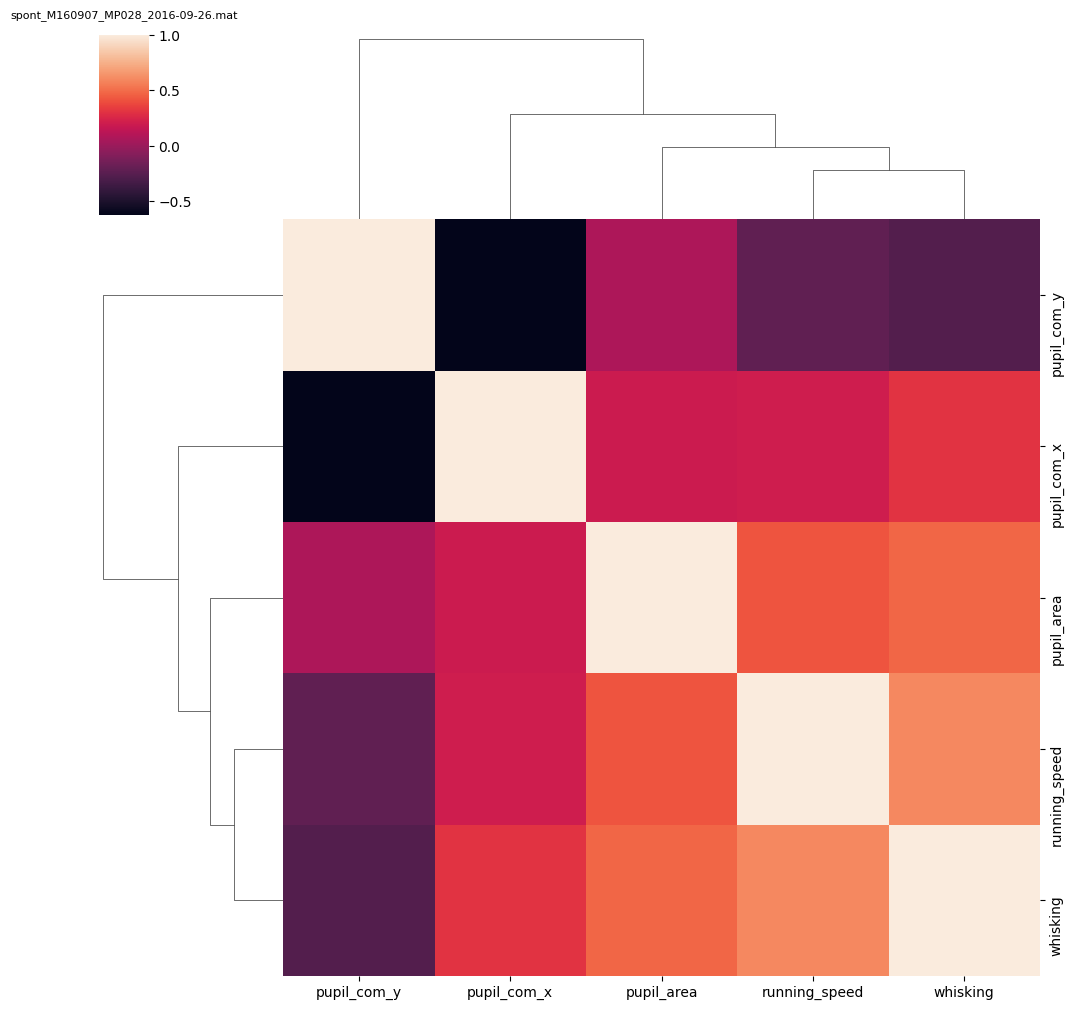

In [28]:
correlation = continuous_behaviors[file_ids.index(plot_id)].corr()
heatmap = sns.clustermap(correlation, yticklabels=True, xticklabels=True)
heatmap.ax_heatmap.set_yticklabels(heatmap.ax_heatmap.get_yticklabels(), fontsize=10)
heatmap.ax_heatmap.set_xticklabels(heatmap.ax_heatmap.get_xticklabels(), fontsize=10)
heatmap.ax_heatmap.tick_params(axis='x', bottom=True, top=False)

plt.title(f'{filenames[file_ids.index(plot_id)]}', y=1.05, fontsize=8)
plt.show()

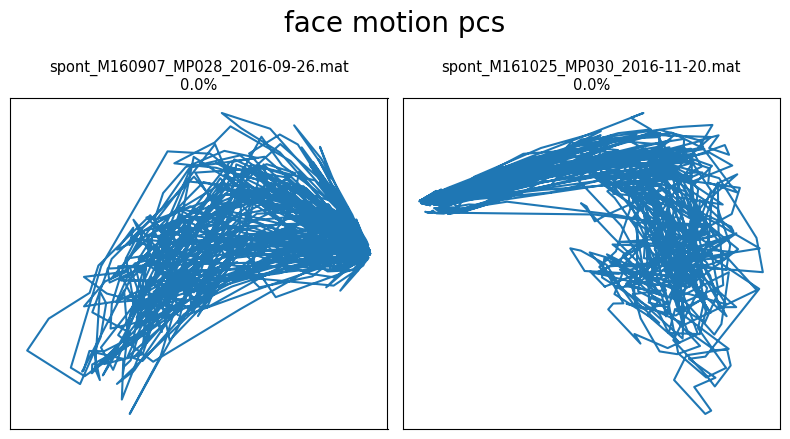

0.0%


In [29]:
plot_utils.plot_manifolds(filenames, [motion_pc[0][['PC1', 'PC2']].iloc[:1500] for motion_pc in motion_pcs], [[0] for _ in range(len(filenames))],
						  title='face motion pcs', top_space=0.25)

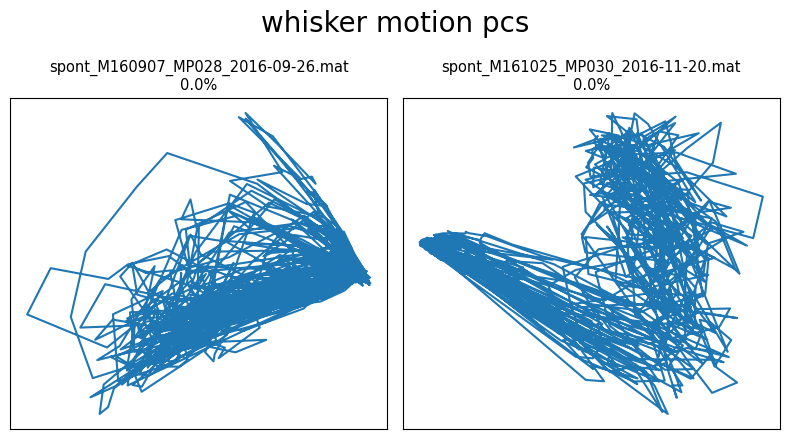

0.0%


In [30]:
plot_utils.plot_manifolds(filenames, [motion_pc[1][['PC1', 'PC2']].iloc[:1500] for motion_pc in motion_pcs], [[0] for _ in range(len(filenames))],
						  title='whisker motion pcs', top_space=0.25)

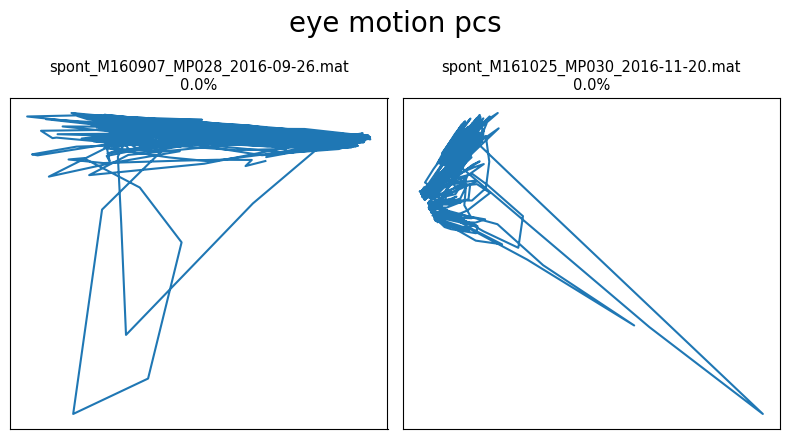

0.0%


In [31]:
plot_utils.plot_manifolds(filenames, [motion_pc[2][['PC1', 'PC2']].iloc[:1500] for motion_pc in motion_pcs], [[0] for _ in range(len(filenames))],
						  title='eye motion pcs', top_space=0.25)

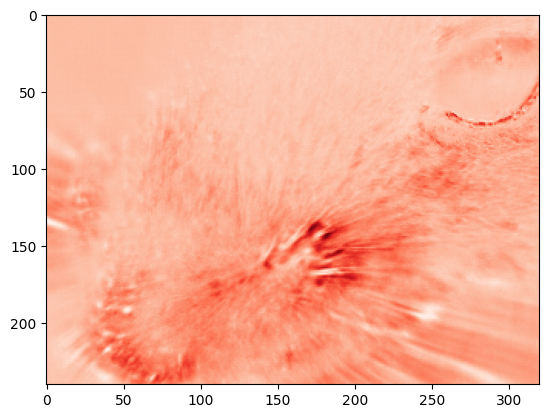

In [32]:
face_weights = motion_pcs[file_ids.index(plot_id)][0]
face_loadings = motion_masks[file_ids.index(plot_id)][0][0]

w1 = face_weights.values[1, :].reshape(1, -1)
l1 = face_loadings.values
f1 = w1 @ l1

ar = motion_masks[file_ids.index(plot_id)][0][1]
f1 = f1.reshape(-1, ar[0], ar[1])

plt.imshow(f1.T, cmap='Reds_r')

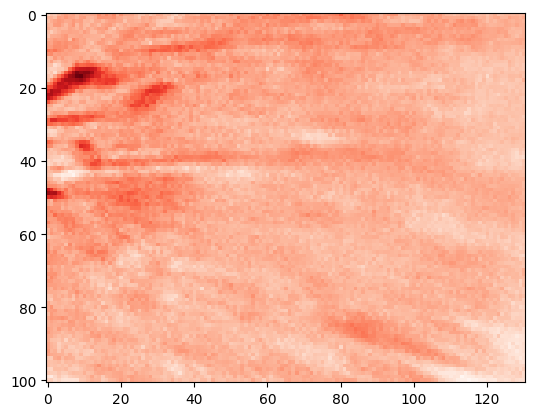

In [33]:
whisk_weights = motion_pcs[file_ids.index(plot_id)][1]
whisk_loadings = motion_masks[file_ids.index(plot_id)][1][0]

w1 = whisk_weights.values[1, :].reshape(1, -1)
l1 = whisk_loadings.values
f1 = w1 @ l1

ar = motion_masks[file_ids.index(plot_id)][1][1]
f1 = f1.reshape(-1, ar[0], ar[1])

plt.imshow(f1.T, cmap='Reds_r')